Imports

In [143]:
%load_ext autoreload
%autoreload 2

from src.utils.data_io import load_dataset, save_dataset
from src.clustering import (
    run_kmeans, plot_kmeans_search, plot_clusters,
    run_dbscan, plot_dbscan_search, plot_dbscan_clusters, select_best, attach_labels,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Import data

In [144]:
df_clean = load_dataset("clean")
df_clustering = load_dataset("clustering")
df_clean.shape, df_clustering.shape

((8949, 7), (8949, 7))

K-means

In [145]:
kmeans = run_kmeans(df_clustering)
kmeans["params"], kmeans["silhouette"]

({'n_components': 2, 'k': 3}, 0.4487397411479185)

In [146]:
kmeans["results"]

,n_components,k,inertia,silhouette
0,2,2,23542.395938,0.430953
1,2,3,13244.219895,0.448740
2,2,4,10414.983259,0.421660
3,2,5,8242.980510,0.410122
4,2,6,6689.621477,0.394669
5,2,7,5634.987347,0.397941
6,3,2,30681.084633,0.368307
7,3,3,20205.727848,0.382649
8,3,4,16448.250736,0.388787
9,3,5,13781.047480,0.390872


K-means search

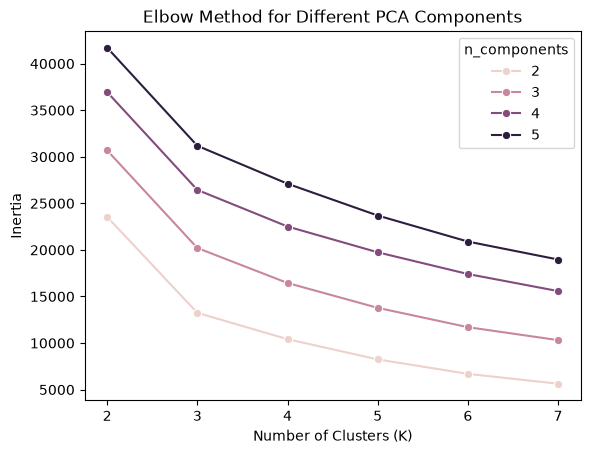

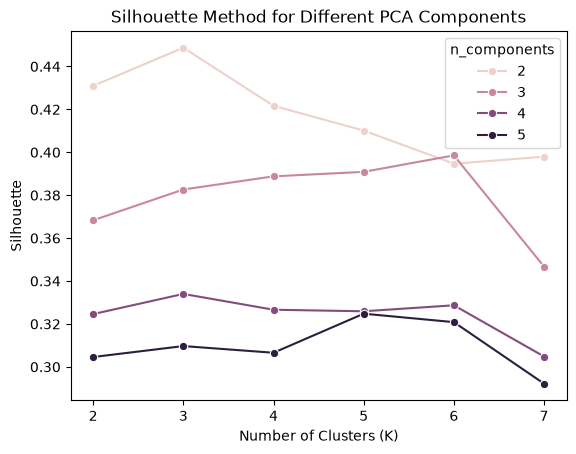

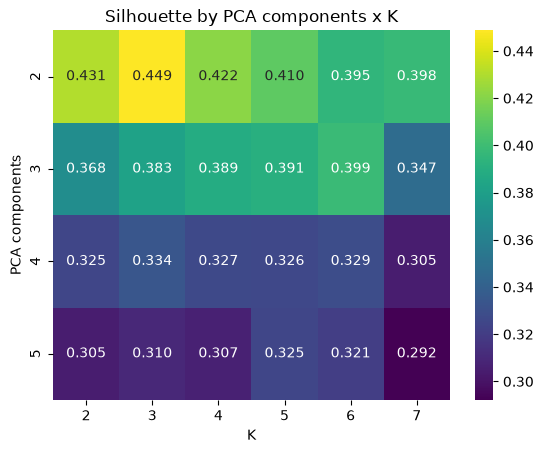

In [147]:
plot_kmeans_search(kmeans["results"])

Clusters

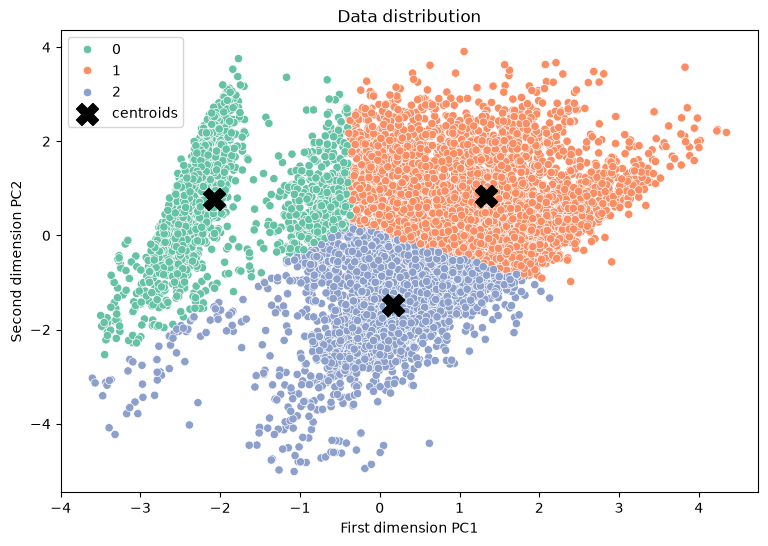

In [148]:
plot_clusters(kmeans)

DBSCAN

In [149]:
dbscan = run_dbscan(df_clustering)
dbscan["params"], dbscan["silhouette"], dbscan["noise"]

({'n_components': 2, 'eps': 0.3, 'min_samples': 20},
 0.4068609736607543,
 np.float64(2.637166163817186))

In [150]:
dbscan["results"].head(10)

,clusters,eps,n_components,min_samples,noise,silhouette,max,min
0,7,0.3,4,20,62.051626,0.512059,50.647821,0.588928
1,7,0.3,5,20,73.706559,0.506597,64.300892,0.637484
2,5,0.3,3,20,15.890044,0.431111,28.895974,0.265710
3,2,0.3,2,5,0.301710,0.421375,99.932751,0.067249
4,3,0.3,2,20,2.637166,0.406861,76.953977,0.275450
5,3,0.3,2,10,1.028048,0.388007,76.956080,0.146777
6,9,0.2,3,20,50.251425,0.384381,39.398023,0.359389
7,2,0.7,3,20,0.983350,0.360124,99.763006,0.236994
8,4,0.5,4,20,12.403621,0.353678,30.705447,19.811200
9,3,1.0,5,20,2.313108,0.352147,98.844658,0.571951


DBSCAN search

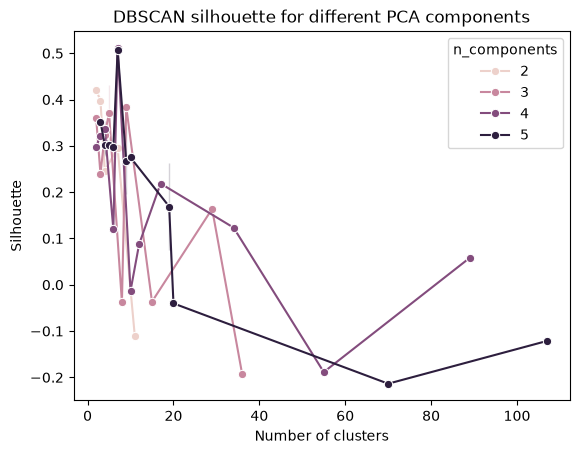

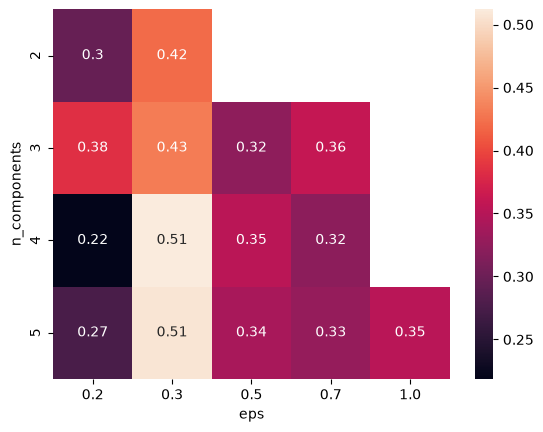

In [151]:
plot_dbscan_search(dbscan["results"])

DBSCAN clusters

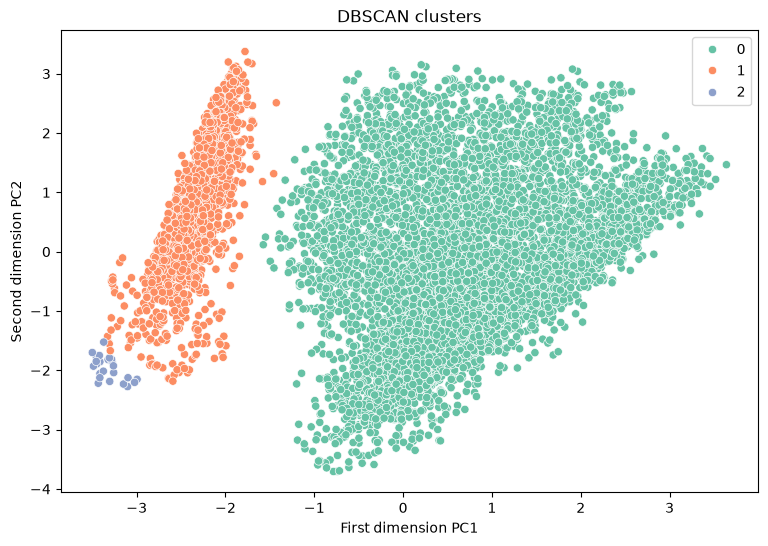

In [152]:
plot_dbscan_clusters(dbscan)

Comparison

In [153]:
method, comparison = select_best(kmeans, dbscan)
print(method)
comparison.round(3)

kmeans


,method,clusters,silhouette,davies_bouldin,calinski_harabasz,noise_%,min_cluster_%,max_cluster_%
0,"K-Means (PCA=2, K=3)",3,0.449,0.774,9198.595,0.000,27.132,37.915
1,"DBSCAN (PCA=2, eps=0.3, ms=20)",3,0.407,0.628,3314.175,2.637,0.275,76.954


Save data

In [154]:
df_clustered = attach_labels(df_clean, kmeans, dbscan, method)
save_dataset(df_clustered, "clustered")
df_clustered["cluster_final"].value_counts(normalize=True).round(3)

cluster_final
1    0.379
2    0.350
0    0.271
Name: proportion, dtype: float64

Means scaled_df

In [155]:
scaled = load_dataset('clustering').assign(cluster_final=df_clustered['cluster_final'])

scaled_res = scaled.groupby('cluster_final').agg(
    avg_balance = ('BALANCE', 'mean'),
    avg_purchases = ('PURCHASES', 'mean'),
    avg_advance_cash = ('CASH_ADVANCE', 'mean'),
    avg_credit_limit = ('CREDIT_LIMIT', 'mean'),
    avg_PAYMENTS = ('PAYMENTS', 'mean'),
)
scaled_res

,avg_balance,avg_purchases,avg_advance_cash,avg_credit_limit,avg_PAYMENTS
cluster_final,,,,,
0,0.496163,-1.402493,1.003312,-0.121804,-0.006280
1,0.454228,0.780181,-0.025051,0.602053,0.568697
2,-0.877838,0.242359,-0.751612,-0.558512,-0.612001


Means clustered_df

In [156]:

res = df_clustered.groupby('cluster_final').agg(
    avg_balance = ('BALANCE', 'mean'),
    avg_purchases = ('PURCHASES', 'mean'),
    avg_advance_cash = ('CASH_ADVANCE', 'mean'),
    avg_credit_limit = ('CREDIT_LIMIT', 'mean'),
    avg_payments = ('PAYMENTS', 'mean'),
).round()


clusters_names = {
    res['avg_advance_cash'].idxmax() : "Card Active Client",
    res['avg_purchases'].idxmax() : "Cash Active Client",
    res['avg_balance'].idxmin() : "Baseline Client"
}

df_clustered['target'] = df_clustered['cluster_final'].map(clusters_names)

save_dataset(df_clustered, 'labeled')

Feature story : 4 Classification

In [177]:
import pandas as  pd
import time

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


features = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS"]
RANDOM_STATE = 42

data = load_dataset('labeled')



models = {
    'LogisticRegression': LogisticRegression(random_state=RANDOM_STATE, solver="saga"),
    'DecisionTreeClassifier': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'RandomForestClassifier': RandomForestClassifier(random_state=RANDOM_STATE),
    'SVC': SVC(random_state=RANDOM_STATE)
}

models_params = {
    'LogisticRegression':  {
        "classifier__C": [0.1, 1, 10],
        "classifier__penalty": ["l1", "l2"]
        },
    'DecisionTreeClassifier': {
        'classifier__criterion': ['gini', 'entropy'],
        'classifier__max_depth': [2, 4, 6, 8, 10, None],
        'classifier__min_samples_split': [2, 5, 10],
    },
    'RandomForestClassifier': {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [None, 10],
        "classifier__max_features": ["sqrt", None]
    },
    'SVC': {
        "classifier__kernel": ["rbf"], "classifier__C": [1, 10],
        "classifier__gamma": ["scale", 0.1]
    }
}

def build_pipline(model):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', model),
    ])

def split_data(df: pd.DataFrame, test_size = 0.2, random_state=42):
    X, Y = df[features], df["target"]
    return train_test_split(X, Y, test_size=test_size, random_state=random_state)


x_train, x_test, y_train, y_test = split_data(data)
result = []

for name, model in models.items():
    grid = GridSearchCV(
        build_pipline(model),
        cv = 3,
        param_grid=models_params[name],
        scoring={
            "f1": "f1_macro",
            "accuracy": "accuracy",
            "precision": "precision_macro",
            "recall": "recall_macro",
        },
        n_jobs=-1,
        refit='f1'
    )
    
    
    start = time.perf_counter()
    grid.fit(x_train, y_train)
    end = time.perf_counter()
    
    i = grid.best_index_
    result.append({
        "name": name,
        "duration" : end - start,
        "model": grid.best_estimator_,
        "best_params": grid.best_params_,
        "accuracy": grid.cv_results_["mean_test_accuracy"][i],
        "precision": grid.cv_results_["mean_test_precision"][i],
        "recall": grid.cv_results_["mean_test_recall"][i],
        "f1": grid.cv_results_["mean_test_f1"][i],
    })


c:\Users\Administrator\Projects\Briefs\Brief 3 - CardProfiler\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Administrator\Projects\Briefs\Brief 3 - CardProfiler\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\Administrator\Projects\Briefs\Brief 3 - CardProfiler\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [171]:
from sklearn.metrics import accuracy_score, classification_report

result = pd.DataFrame(result)
result.sort_values(by='f1', ascending=False)

,name,duration,model,best_params,accuracy,precision,recall,f1
2,RandomForestClassifier,4.091072,"(StandardScaler(), (DecisionTreeClassifier(max...","{'classifier__max_depth': 10, 'classifier__max...",0.964520,0.965179,0.964915,0.964986
1,DecisionTreeClassifier,0.555336,"(StandardScaler(), DecisionTreeClassifier(crit...","{'classifier__criterion': 'entropy', 'classifi...",0.938540,0.940076,0.940268,0.940043
3,SVC,0.755384,"(StandardScaler(), SVC(C=10, random_state=42))","{'classifier__C': 10, 'classifier__gamma': 'sc...",0.937982,0.937189,0.939785,0.938212
0,LogisticRegression,0.677893,"(StandardScaler(), LogisticRegression(C=1, pen...","{'classifier__C': 1, 'classifier__penalty': 'l1'}",0.897473,0.897121,0.900357,0.897993


([0, 1, 2, 3],
 [Text(0, 0, 'LogisticRegression'),
  Text(1, 0, 'DecisionTreeClassifier'),
  Text(2, 0, 'RandomForestClassifier'),
  Text(3, 0, 'SVC')])

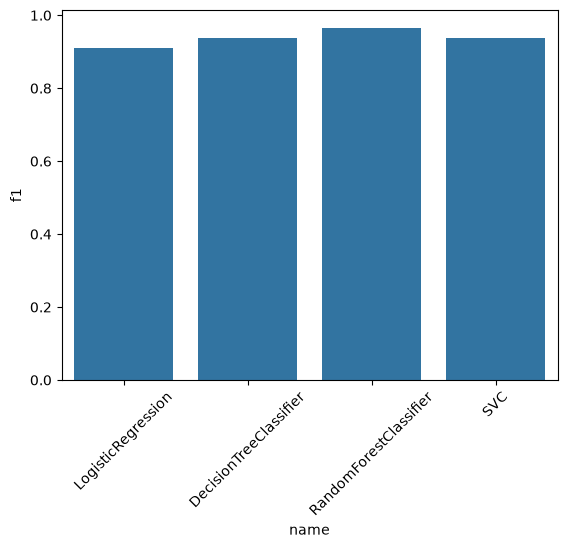

In [163]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

sns.barplot(data=result, x='name', y='f1')
plt.xticks(rotation=45)

    

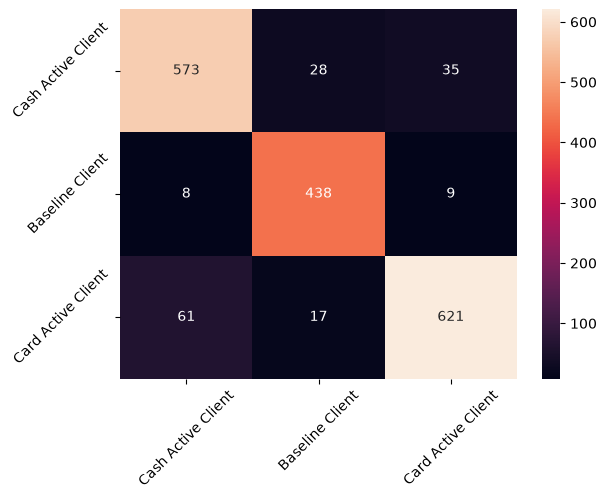

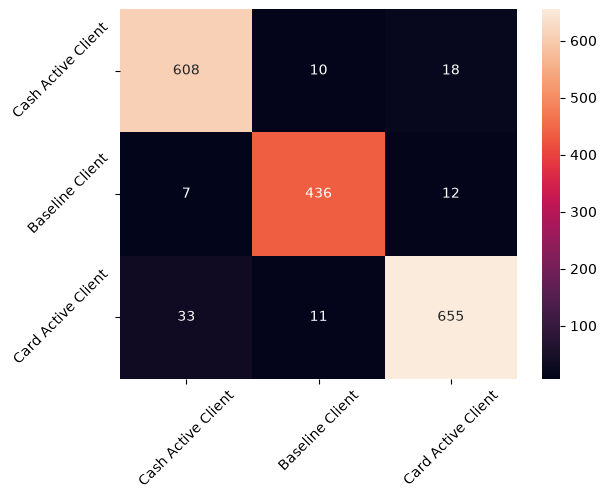

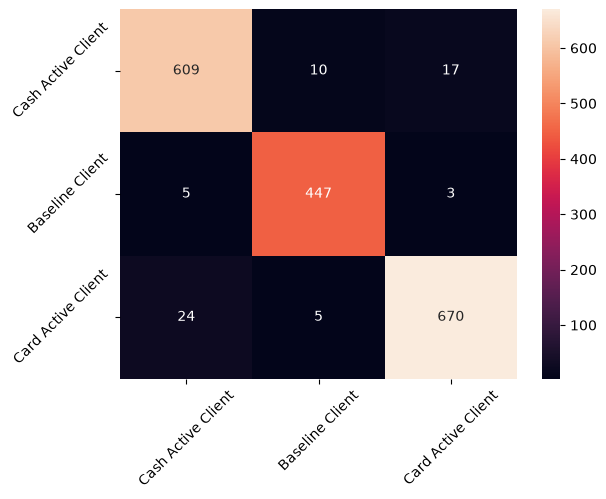

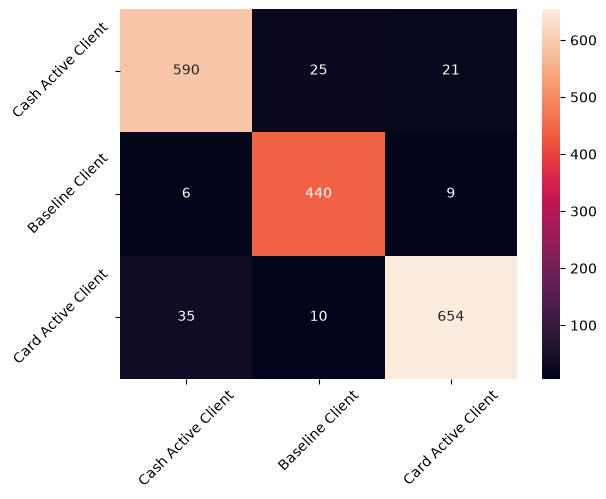

In [164]:



for i, model in enumerate(result['model']):
    sns.heatmap(data=confusion_matrix(y_test, model.predict(x_test)), fmt="d", annot=True, yticklabels=y_test.unique(), xticklabels=y_test.unique())
    plt.xticks(rotation=45)
    plt.yticks(rotation=45)
    plt.show()

In [165]:

from src.utils.data_io import save_pipeline


best = result.sort_values(by='f1', ascending=False).loc[0]
best_model = best['model']
y_predict = best_model.predict(x_test)

report = pd.DataFrame(classification_report(y_test, y_predict, output_dict=True))
accuracy = accuracy_score(y_test, y_predict)
report


,Baseline Client,Card Active Client,Cash Active Client,accuracy,macro avg,weighted avg
precision,0.892523,0.906832,0.933835,0.911732,0.911063,0.912293
recall,0.900943,0.962637,0.888412,0.911732,0.917331,0.911732
f1-score,0.896714,0.933902,0.910557,0.911732,0.913724,0.911572
support,636.000000,455.000000,699.000000,0.911732,1790.000000,1790.000000


Serialize thhe best Model (Pipline)

In [167]:
save_pipeline(best_model)

WindowsPath('C:/Users/Administrator/Projects/Briefs/Brief 3 - CardProfiler/models/cardprofiler_pipeline.joblib')

,Baseline Client,Card Active Client,Cash Active Client
precision,0.892523,0.906832,0.933835
recall,0.900943,0.962637,0.888412
f1-score,0.896714,0.933902,0.910557


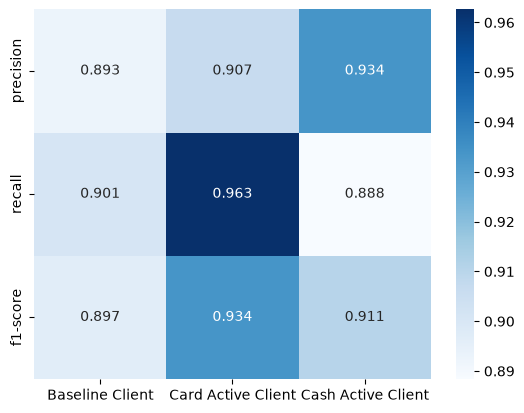

In [166]:
metrics = report.loc[
    ['precision', 'recall', 'f1-score'],
    ['Baseline Client', 'Card Active Client', 'Cash Active Client']
]

sns.heatmap(
    metrics,
    annot=True,
    fmt=".3f",
    cmap="Blues"
)
metrics